# Data understanding: a bounded catalog pilot

Experiment **data-pilot-v1**, acquired 2026-10-12. Work package 1 is **incomplete**:
text and catalog access are verified, but images and reference rasters are absent.
No encoder, reference rules, query benchmark, or retrieval experiment is implemented.

## 1. Which data do we need, and why?

Sentinel-2 B04/B03/B02 provide the planned visual input. BigEarthNet.txt adds
language annotations; the v2 catalog establishes pair identity. Native reference
maps will support a separate evaluation stage. Text answers do not substitute for
maps or independently verified visual content. Sources, licenses, schema, and
access limits are documented in [data access](../docs/DATA_ACCESS.md).

## 2. Configuration and reproducible selection

We use the first ten distinct S2 patch IDs in ascending server row order within
rows 0–399. Selection does not inspect labels or model results. This convenience
sample is geographically concentrated and is not a representative benchmark.
The unversioned rows API is pinned by response SHA-256; changed responses fail
rather than silently replacing the pilot. Public manifests contain no local paths.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from earth_observation.data import load_pilot
from earth_observation.raster import patch_files, inspect_patch, load_rgb

ROOT = Path.cwd().parent
MANIFEST = ROOT / "manifests/data-pilot-v1.json"
CACHE = ROOT / "data/cache"
IMAGE_ROOT = ROOT / "data/raw/BigEarthNet-S2"
MAP_ROOT = ROOT / "data/raw/Reference_Maps"
DISPLAY_UPPER_DN = 3000

manifest = json.loads(MANIFEST.read_text())
patches, catalog = load_pilot(MANIFEST, CACHE)
assert len(patches) == 10
pd.DataFrame(manifest["assets"])[["name", "size_bytes"]]

,name,size_bytes
0,text-rows-0.json,55921
1,text-rows-100.json,56875
2,text-rows-200.json,55627
3,text-rows-300.json,58107
4,metadata.parquet,3616349


The bounded acquisition consists of four annotation pages and one catalog
Parquet file. Cached files are checked before reuse. Large image and map archives
are deliberately excluded from automatic acquisition.

## 3. Can the text and catalog be matched exactly?

Repeated patch IDs in the text are expected: each row is a separate instruction.
Pilot patch IDs must be unique. We join exact S2 IDs against independent v2
metadata and check the S1 pair name; filenames alone would be insufficient.

In [2]:
catalog[["patch_id", "catalog_status", "country", "split"]]

,patch_id,catalog_status,country,split
0,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
1,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
2,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
3,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
4,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
5,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
6,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
7,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
8,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
9,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test


All ten exact patch identities and S1 pair names agree with the catalog.
All selected patches are in Austria, from one S2 tile, and carry the source `test`
split. This source split is reported metadata, not our project's final test set.
The sample must not guide future frozen evaluation choices. No raster identity or
alignment is established by a catalog join.

In [3]:
pd.DataFrame(patches)[["row_idx", "ID", "patch_id", "type", "category"]].head(3)

,row_idx,ID,patch_id,type,category
0,0,1,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency
1,25,26,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency
2,49,50,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency


The first instruction for these examples is an adjacency annotation.
It is useful for inspecting the schema, but neither annotation order nor an answer
constitutes a retrieval relevance rule. No such rule is derived in this notebook.

## 4. Are RGB and map examples actually available?

Expected files follow the official tile/patch layout. We check local existence
first, then native raster dimensions, CRS, affine transform, resolution and extent.
Different reference resolution is permitted when footprints agree; RGB bands
must share one grid. No resampling, reprojection, or repair is performed.

In [4]:
files_by_patch = {p["patch_id"]: patch_files(p["patch_id"], IMAGE_ROOT, MAP_ROOT)
                  for p in patches}
checks = {patch_id: inspect_patch(files)
          for patch_id, files in files_by_patch.items()}
availability = pd.DataFrame([
    {"patch_id": patch_id, "raster_status": check["status"],
     "missing_components": ", ".join(check["missing"])}
    for patch_id, check in checks.items()
])
availability

,patch_id,raster_status,missing_components
0,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
1,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
2,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
3,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
4,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
5,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
6,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
7,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
8,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"
9,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,incomplete,"B04, B03, B02, reference"


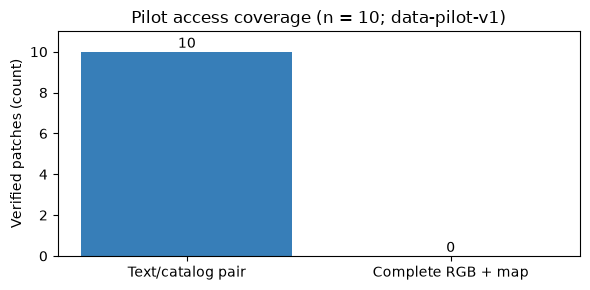

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
counts = [int((catalog["catalog_status"] == "verified").sum()),
          sum(c["status"] == "aligned" for c in checks.values())]
ax.bar(["Text/catalog pair", "Complete RGB + map"], counts, color=["#377eb8", "#999999"])
ax.set(ylabel="Verified patches (count)", ylim=(0, 11),
       title="Pilot access coverage (n = 10; data-pilot-v1)")
for i, value in enumerate(counts):
    ax.text(i, value + .2, str(value), ha="center")
fig.tight_layout()
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/data-pilot-v1-availability.png", dpi=120)
plt.show()

At acquisition, all ten patches lack all three RGB files and the reference
map. Thus **zero** real RGB/map examples or spatial checks have passed. The plot
reports access coverage only. Both archives returned HTTP 206 for 1-KiB probes;
byte ranges alone do not provide an indexed path to a selected compressed tar member.
No full archive was downloaded.

### Display policy for a future local subset

The display clips raw DN / 3000 to [0, 1], with fixed scaling across patches.
This is a visualization choice, not model preprocessing or calibrated reflectance.
Raster-declared masks/NoData and nonfinite values make the whole RGB pixel unknown;
zero is retained if not declared NoData. A reference is shown in its native grid,
without inferring land-cover classes from colors. Maps are annotations rather than
visually confirmed truth. The following step explicitly skips absent real examples.

In [6]:
complete = [p for p, c in checks.items() if c["status"] == "aligned"]
if not complete:
    print("BLOCKED: representative RGB/reference examples require a real local subset.")
else:
    import rasterio
    for patch_id in complete[:2]:
        files = files_by_patch[patch_id]
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        axes[0].imshow(load_rgb(files, upper=DISPLAY_UPPER_DN))
        axes[0].set_title("RGB: fixed raw DN / 3000")
        with rasterio.open(files["reference"]) as ds:
            reference = ds.read(1, masked=True)
        image = axes[1].imshow(reference, interpolation="nearest", cmap="tab20")
        axes[1].set_title("Reference: raw class IDs")
        fig.colorbar(image, ax=axes[1], label="Source class ID")
        for ax in axes:
            ax.set(xlabel="Native pixel column", ylabel="Native pixel row")
        fig.suptitle(patch_id + " (single patch)", fontsize=8)
        fig.tight_layout()
        plt.show()

BLOCKED: representative RGB/reference examples require a real local subset.


## 5. What is verified, and what remains?

Verified: checksum-pinned text/catalog acquisition, deterministic ten-patch
selection, exact S2/S1 catalog identity, and explicit detection of missing rasters.
The accompanying controlled tests exercise cache drift, duplicate IDs, missing
references, RGB channel order/NoData, shifted grids, CRS mismatch and differing
map resolutions. Synthetic tests validate implementation, not real data access.

Blocked: real image/reference loading, observed raster schema and spatial
alignment, representative RGB/map inspection, and a complete raster integration
test. There are no scientific retrieval findings. The PNG saved under `outputs/`
is an access diagnostic; source snapshots remain in ignored `data/cache/`.

Next: obtain an independently verifiable bounded v2 subset (or an official member
index/access route), finish real raster integration and visual inspection, then
complete work package 1 before implementing reference rules in work package 2.